# Influenza in England: before, during and after COVID-19

**Question:** How did flu circulate before, during and after the COVID-19 pandemic, and was the surge
in winter 2022/23 a real increase in illness, everywhere in England at once?

**Data:** UK Health Security Agency (UKHSA) data dashboard API. Weekly influenza PCR test positivity and
hospital admission rates, England and the 9 UKHSA Regions, 2018 to 2024.

**Measures used**
- **Test positivity:** % of influenza PCR tests that were positive (positive tests ÷ all tests × 100).
  It describes people who were tested, not the whole population.
- **Hospital admission rate:** people admitted to hospital with flu in one week, per 100,000 people living in the area.



In [13]:

import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ipywidgets as wdg
from IPython.display import display

%matplotlib inline
plt.rcParams['figure.dpi'] = 100

for f in ["influenza_positivity.json", "influenza_regions.json"]:
    print(f, "found" if os.path.exists(PAUL + f) else "MISSING")

influenza_positivity.json found
influenza_regions.json found


## Influenza positivity in England, 2018 to 2024

The shaded band marks the main period of COVID-19 restrictions. Switch to the **log** scale to see
the very low values during the restrictions.

In [31]:
# England positivity: load straight from the JSON made by part1_influenza_positivity.py
with open(PAUL + "influenza_positivity.json", "rt") as INFILE:
    rows = json.load(INFILE)
rows = [row for row in rows if row.get('age', 'all') == 'all']
england = pd.Series({pd.to_datetime(row['date'], format="%Y-%m-%d"): row['metric_value']
                     for row in rows}).sort_index()
print("England positivity:", england.index[0].date(), "to", england.index[-1].date(),
      f"({len(england)} weeks)")


def draw_england(scale):
    """Line graph of England positivity, on a linear or log scale."""
    fig, ax = plt.subplots(figsize=(10, 4.5))
    # shade the main COVID-19 restriction period
    ax.axvspan(pd.Timestamp("2020-03-23"), pd.Timestamp("2022-02-24"), color="lightgrey", alpha=0.5)
    if scale == "log":
        # a log scale can't show 0, so leave weeks with 0 as gaps
        ax.plot(england.index, england.where(england > 0), color="#1D9E75")
        ax.set_yscale("log")
    else:
        ax.plot(england.index, england, color="#1D9E75")
    ax.set_title(f"Influenza test positivity, England, {england.index[0].year} to {england.index[-1].year}")
    ax.set_ylabel("% of influenza PCR tests that were positive\n(positive tests ÷ all tests × 100), weekly")
    ax.set_xlabel("Date (each point = one week)")
    # label the shaded band inside it, near the top
    ax.text(pd.Timestamp("2021-03-01"), 0.97, "Main COVID-19\nrestriction period", ha="center", va="top",
            transform=ax.get_xaxis_transform(), fontsize=9, color="dimgrey")
    fig.text(0.01, 0.01, "Positivity = share of flu tests that were positive, not share of the population. "
             "Source: UKHSA data dashboard API.", fontsize=9, color="dimgrey")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()

England positivity: 2018-01-01 to 2024-12-30 (366 weeks)


In [3]:
england_scale = wdg.ToggleButtons(options=["linear", "log"], value="linear", description="Scale:")
display(england_scale, wdg.interactive_output(draw_england, {"scale": england_scale}))

ToggleButtons(description='Scale:', options=('linear', 'log'), value='linear')

Output()

## Hospital admissions in England 



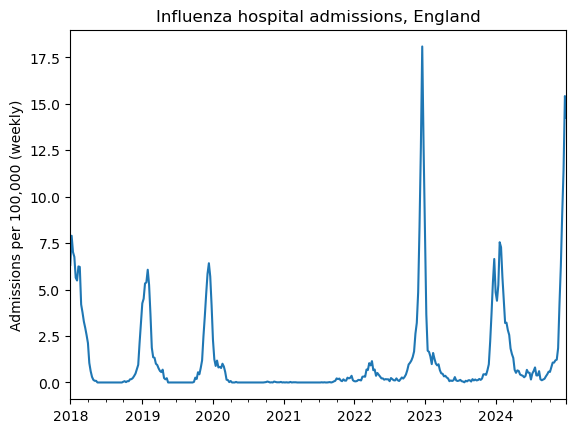

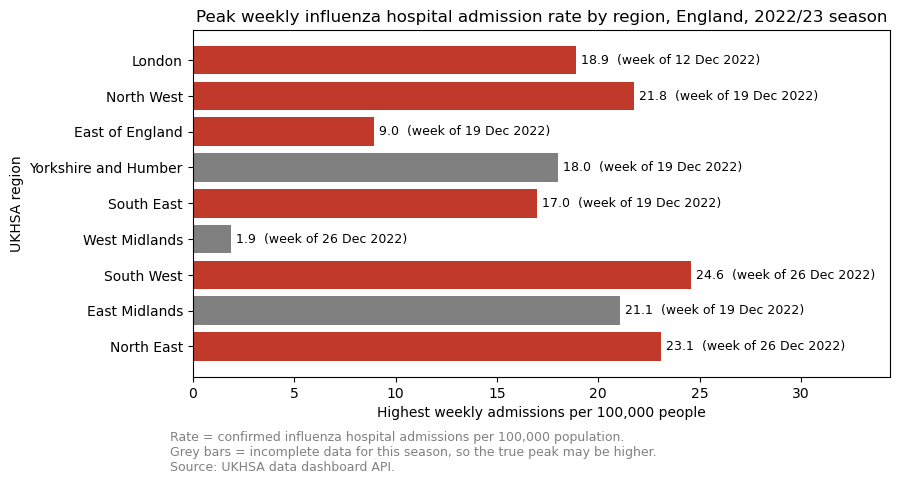

In [34]:
import requests
import time
import json
import pandas as pd
import matplotlib.pyplot as plt


class APIwrapper:
    # class variables shared among all instances
    _access_point="https://api.ukhsa-dashboard.data.gov.uk"
    _last_access=0.0 # time of last api access

    def __init__(self, theme, sub_theme, topic, geography_type, geography, metric):
        """ Init the APIwrapper object, constructing the endpoint from the structure
        parameters """
        # build the path with all the required structure parameters. You do not need to edit this line,
        # parameters will be replaced by the actual values when you instantiate an object of the class!
        url_path=(f"/themes/{theme}/sub_themes/{sub_theme}/topics/{topic}/geography_types/" +
                  f"{geography_type}/geographies/{geography}/metrics/{metric}")
        # our starting API endpoint
        self._start_url=APIwrapper._access_point+url_path
        self._filters=None
        self._page_size=-1
        # will contain the number of items
        self.count=None

    def get_page(self, filters={}, page_size=5):
        """ Access the API and download the next page of data. Sets the count
        attribute to the total number of items available for this query. Changing
        filters or page_size will cause get_page to restart from page 1. Rate
        limited to three request per second. The page_size parameter sets the number
        of data points in one response page (maximum 365); use the default value
        for debugging your structure and filters. """
        # Check page size is within range
        if page_size>365:
            raise ValueError("Max supported page size is 365")
        # restart from first page if page or filters have changed
        if filters!=self._filters or page_size!=self._page_size:
            self._filters=filters
            self._page_size=page_size
            self._next_url=self._start_url
        # signal the end of data condition
        if self._next_url==None:
            return [] # we already fetched the last page
        # simple rate limiting to avoid bans
        curr_time=time.time() # Unix time: number of seconds since the Epoch
        deltat=curr_time-APIwrapper._last_access
        if deltat<0.33: # max 3 requests/second
            time.sleep(0.33-deltat)
        APIwrapper._last_access=curr_time
        # build parameter dictionary by removing all the None
        # values from filters and adding page_size
        parameters={x: y for x, y in filters.items() if y!=None}
        parameters['page_size']=page_size
        # the page parameter is already included in _next_url.
        # This is the API access. Response is a dictionary with various keys.
        # the .json() method decodes the response into Python object (dictionaries,
        # lists; 'null' values are translated as None).
        response = requests.get(self._next_url, params=parameters).json()
        # update url so we'll fetch the next page
        self._next_url=response['next']
        self.count=response['count']
        # data are in the nested 'results' list
        return response['results']

    def get_all_pages(self, filters={}, page_size=365):
        """ Access the API and download all available data pages of data. Sets the count
        attribute to the total number of items available for this query. API access rate
        limited to three request per second. The page_size parameter sets the number
        of data points in one response page (maximum 365), and controls the trade-off
        between time to load a page and number of pages; the default should work well
        in most cases. The number of items returned should in any case be equal to
        the count attribute. """
        data=[] # build up all data here
        while True:
            # use get_page to do the job, including the pacing
            next_page=self.get_page(filters, page_size)
            if next_page==[]:
                break # we are done
            data.extend(next_page)
        return data


# Graph 1: hospital admissions rate per week 2018-2024 England

# download
structure = {"theme": "infectious_disease",
             "sub_theme": "respiratory",
             "topic": "Influenza",
             "geography_type": "Nation",
             "geography": "England",
             "metric": "influenza_healthcare_hospitalAdmissionRateByWeek"}

api = APIwrapper(**structure)
flu_admissions = api.get_all_pages()

with open("flu_admissions.json", "wt") as OUTF:
    json.dump(flu_admissions, OUTF)


def parse_date(datestring):
    return pd.to_datetime(datestring, format="%Y-%m-%d")

# date
data = {}
for entry in flu_admissions:
    if entry["age"] == "all":
        data[entry["date"]] = entry["metric_value"]

dates = sorted(data.keys())
startdate = parse_date(dates[0])
enddate = parse_date(dates[-1])

# weekly index on the same weekday as the data
weekday = startdate.day_name()[:3].upper()
index = pd.date_range(startdate, enddate, freq="W-" + weekday)
flu_df = pd.DataFrame(index=index, columns=["admission_rate"])

# fill in values
for date, value in data.items():
    flu_df.loc[parse_date(date), "admission_rate"] = value

flu_df = flu_df.astype(float)

# plot
flu_period = flu_df.loc["2018-01-01":"2024-12-31"]

ax = flu_period.plot(legend=False)
ax.set_title("Influenza hospital admissions, England")
ax.set_ylabel("Admissions per 100,000 (weekly)")
ax.set_xlabel("")


# Graph 2: peak weekly rate per region in the 2022/23 season 

# download
regions = ["London", "North West", "East of England", "Yorkshire and Humber", "South East",
           "West Midlands", "South West", "East Midlands", "North East"]

region_admissions = {}          # region name -> list of entries
for region in regions:
    structure = {"theme": "infectious_disease",
                 "sub_theme": "respiratory",
                 "topic": "Influenza",
                 "geography_type": "UKHSA Region",
                 "geography": region,
                 "metric": "influenza_healthcare_hospitalAdmissionRateByWeek"}
    api = APIwrapper(**structure)
    region_admissions[region] = api.get_all_pages()

with open("flu_admissions_regions.json", "wt") as OUTF:
    json.dump(region_admissions, OUTF)

# peak region and amount of weeks data
peaks = {}
weeks_with_data = {}
for region, entries in region_admissions.items():
    for e in entries:
        if "2022-09-01" <= e["date"] <= "2023-08-31" and e["age"] == "all":
            weeks_with_data[region] = weeks_with_data.get(region, 0) + 1
            if region not in peaks or e["metric_value"] > peaks[region][0]:
                peaks[region] = (e["metric_value"], e["date"])

# fix order and highlight low data regions
order = [r for r in regions if r in peaks]
values = [peaks[r][0] for r in order]
weeks = [pd.to_datetime(peaks[r][1]).strftime("%d %b %Y") for r in order]
colours = ["#c0392b" if weeks_with_data[r] >= 50 else "grey" for r in order]

# chart
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(order, values, color=colours)
ax.invert_yaxis()                                   # first region in the list at the top
for i, (v, w) in enumerate(zip(values, weeks)):
    ax.text(v + max(values) * 0.01, i, f"{v:.1f}  (week of {w})", va="center", fontsize=9)
ax.set_xlim(0, max(values) * 1.4)
ax.set_title("Peak weekly influenza hospital admission rate by region, England, 2022/23 season")
ax.set_xlabel("Highest weekly admissions per 100,000 people")
ax.set_ylabel("UKHSA region")
fig.text(0.1, -0.1, "Rate = confirmed influenza hospital admissions per 100,000 population.\n"
         "Grey bars = incomplete data for this season, so the true peak may be higher.\n"
         "Source: UKHSA data dashboard API.", fontsize=9, color="grey")
plt.show()

## Influenza by region

Each heat map row is a UKHSA region and each column is one week of the flu season (September to May).
The darker the square, the more flu that week. Grey squares are weeks with no data.

- **Test positivity** (% of influenza PCR tests positive) covers 2018 to 2024, so it includes winters before COVID-19.
- **Hospital admissions** (per 100,000 people) by region are only published from September 2020.

Use the **slider** to move between seasons. The **colour scale** buttons switch between one scale for all
seasons (best for comparing how big each season was) and a scale fitted to the chosen season
(best for seeing timing in quiet seasons such as the COVID-19 years; check the colour key's maximum).

In [28]:
with open(PAUL + "influenza_regions.json", "rt") as INFILE:
    all_rows = json.load(INFILE)
print("Rows loaded:", len(all_rows))

# The two measures: API metric name, chart title, colour key label
measures = {
    "positivity": {"metric": "influenza_testing_positivityByWeek",
                   "title": "Influenza test positivity by region",
                   "key": "% of influenza PCR tests that were positive\n(positive ÷ all tests × 100), weekly",
                   "note": "Positivity = share of flu tests that were positive, not share of the population."},
    "admissions": {"metric": "influenza_healthcare_hospitalAdmissionRateByWeek",
                   "title": "Influenza hospital admissions by region",
                   "key": "Weekly hospital admissions per\n100,000 people living in the region",
                   "note": "Rate = people admitted to hospital with flu in one week, per 100,000 people living in the region."},
}

# For each measure, build a table: one row per week, one column per region
tables = {}
for name, info in measures.items():
    rows = [row for row in all_rows
            if row['metric'] == info['metric'] and row.get('age', 'all') == 'all']
    if len(rows) == 0:
        print(f"{name}: no data in the file, skipping")
        continue
    longdf = pd.DataFrame(rows)
    longdf['date'] = pd.to_datetime(longdf['date'], format="%Y-%m-%d")
    table = longdf.pivot_table(index='date', columns='geography',
                               values='metric_value', aggfunc='mean')
    tables[name] = table
    print(f"{name}: {len(table)} weeks, {table.index[0].date()} to {table.index[-1].date()}, "
          f"{len(table.columns)} regions")

Rows loaded: 4724
positivity: 366 weeks, 2018-01-01 to 2024-12-30, 9 regions
admissions: 190 weeks, 2020-09-28 to 2024-05-13, 9 regions


In [29]:
# Order the regions roughly south to north, so a wave moving across the
# country shows up as a diagonal. Any region not in this list goes at the end.
south_to_north = ["London", "South East", "South West", "East of England",
                  "East Midlands", "West Midlands", "Yorkshire and Humber",
                  "North West", "North East"]


def season_start_year(date):
    """A flu season runs from September to the following summer,
    so September 2022 to August 2023 is season 2022/23."""
    if date.month >= 9:
        return date.year
    return date.year - 1


def season_label(start_year):
    """2022 -> '2022/23'"""
    return f"{start_year}/{str(start_year + 1)[2:]}"


# Number of weeks shown per season: 1 September to the end of May
N_WEEKS = 39

# For each measure: one grid per season (rows = regions, columns = week of season)
grids = {}          # grids[measure][season] = 2D array
region_orders = {}  # region_orders[measure] = list of regions, south to north
overall_max = {}    # overall_max[measure] = highest value in any season
for name, table in tables.items():
    order = [r for r in south_to_north if r in table.columns]
    order += [r for r in table.columns if r not in order]
    region_orders[name] = order
    grids[name] = {}
    for start_year in sorted(set(season_start_year(d) for d in table.index)):
        season_start = pd.Timestamp(year=start_year, month=9, day=1)
        grid = np.full((len(order), N_WEEKS), np.nan)
        in_season = table[(table.index >= season_start) &
                          (table.index < season_start + pd.Timedelta(weeks=N_WEEKS))]
        for date, values in in_season.iterrows():
            week = (date - season_start).days // 7
            for r, region in enumerate(order):
                grid[r, week] = values[region]
        # keep only seasons with at least some data
        if not np.all(np.isnan(grid)):
            grids[name][season_label(start_year)] = grid
    overall_max[name] = max(np.nanmax(g) for g in grids[name].values())
    print(f"{name} seasons:", list(grids[name].keys()))

# Labels along the bottom: where each month starts, in weeks
month_names = ["Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May"]
month_ticks = [i * 52 / 12 for i in range(len(month_names))]


def draw_heatmap(measure, season, colour_scale):
    """Draw the heat map for one measure and one season."""
    grid = grids[measure][season]
    if colour_scale == "Same for all seasons":
        top = overall_max[measure]
    else:
        top = np.nanmax(grid)

    # Colour map: pale yellow (low) to dark red (high); grey for missing weeks
    cmap = plt.get_cmap("YlOrRd").copy()
    cmap.set_bad("lightgrey")

    fig, ax = plt.subplots(figsize=(10, 4))
    image = ax.imshow(np.ma.masked_invalid(grid), aspect="auto", cmap=cmap,
                      vmin=0, vmax=top, interpolation="nearest")
    ax.set_yticks(range(len(region_orders[measure])))
    ax.set_yticklabels(region_orders[measure])
    ax.set_xticks(month_ticks)
    ax.set_xticklabels(month_names)
    ax.set_title(f"{measures[measure]['title']}, England, {season} season")
    ax.set_xlabel("Month of the flu season (each square = one week)")
    ax.set_ylabel("UKHSA region")
    bar = fig.colorbar(image, ax=ax)
    bar.set_label(measures[measure]['key'])
    fig.text(0.01, 0.01, measures[measure]['note'] +
             "\nGrey = no data reported that week. Source: UKHSA data dashboard API.",
             fontsize=9, color="dimgrey")
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()  # important: the chart won't update without this


def make_controls(measure):
    """Create a season slider and colour scale buttons for one measure,
    connect them to draw_heatmap, and show them with the chart."""
    seasons = list(grids[measure].keys())
    season_slider = wdg.SelectionSlider(
        options=seasons,
        value="2022/23" if "2022/23" in seasons else seasons[-1],  # open on the surge
        description="Season:",
        continuous_update=False,  # redraw when the slider is released
        layout=wdg.Layout(width="420px"),
    )
    scale_buttons = wdg.ToggleButtons(
        options=["Same for all seasons", "Fitted to this season"],
        value="Same for all seasons",
        description="Colour scale:",
    )

    def draw(season, colour_scale):
        draw_heatmap(measure, season, colour_scale)

    output = wdg.interactive_output(draw, {"season": season_slider,
                                           "colour_scale": scale_buttons})
    display(wdg.VBox([season_slider, scale_buttons]), output)

positivity seasons: ['2017/18', '2018/19', '2019/20', '2020/21', '2021/22', '2022/23', '2023/24', '2024/25']
admissions seasons: ['2020/21', '2021/22', '2022/23', '2023/24']


### Test positivity by region, 2018 to 2024

Slide from a pre-COVID winter (2018/19 or 2019/20), through the COVID-19 years (2020/21, 2021/22), to 2022/23.

In [6]:
if "positivity" in grids:
    make_controls("positivity")
else:
    print("No regional positivity data in influenza_regions.json")

Output()

### Hospital admissions by region, 2020 to 2024

Regional admissions are only published from September 2020, so there are no pre-COVID seasons here.

In [17]:
if "admissions" in grids:
    make_controls("admissions")
else:
    print("No regional admissions data in influenza_regions.json")

Output()

### Which region was hit hardest? Peak week by region

One bar per region: the **highest weekly value** in the chosen season, sorted from highest to lowest,
with the week it happened. Regions with data for fewer than half the weeks of the season are shown
in **grey** and labelled *incomplete data*, because their real peak may be in a missing week.

In [18]:
MIN_SHARE = 0.5  # a region needs data for at least half the season's weeks to count as complete

def draw_peak_bars(measure, season):
    """Bar chart of each region's highest weekly value in one season."""
    if season not in grids[measure]:
        print(f"No regional {measure} data for {season}. Seasons available: {list(grids[measure].keys())}")
        return
    table = tables[measure]
    start_year = int(season[:4])
    season_start = pd.Timestamp(year=start_year, month=9, day=1)
    in_season = table[(table.index >= season_start) &
                      (table.index < season_start + pd.Timedelta(weeks=N_WEEKS))]

    # one row per region: peak value, week of the peak, number of weeks with data
    summary = []
    for region in region_orders[measure]:
        values = in_season[region]
        weeks_with_data = values.notna().sum()
        if weeks_with_data == 0:
            continue  # no data at all this season
        summary.append({"region": region,
                        "peak": values.max(),
                        "week": values.idxmax(),
                        "complete": weeks_with_data >= MIN_SHARE * N_WEEKS,
                        "weeks": weeks_with_data})
    summary.sort(key=lambda row: row["peak"])  # lowest first, so the highest is at the top

    colours = ["#c0392b" if row["complete"] else "lightgrey" for row in summary]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.barh([row["region"] for row in summary], [row["peak"] for row in summary], color=colours)
    biggest = max(row["peak"] for row in summary)
    for i, row in enumerate(summary):
        label = f"{row['peak']:.1f}  (week of {row['week'].strftime('%d %b %Y')})"
        if not row["complete"]:
            label += f"  incomplete data: {row['weeks']} of {N_WEEKS} weeks"
        ax.text(row["peak"] + biggest * 0.01, i, label, va="center", fontsize=9)
    ax.set_xlim(0, biggest * 1.6)  # room for the labels
    peak_titles = {"positivity": "Peak weekly influenza PCR test positivity by region",
                   "admissions": "Peak weekly influenza hospital admissions by region"}
    ax.set_title(f"{peak_titles.get(measure, measure)}, England, {season} season")
    peak_labels = {"positivity": "Highest weekly % of influenza PCR tests that were positive (positive tests ÷ all tests × 100)",
                   "admissions": "Highest weekly hospital admissions per 100,000 people living in the region"}
    ax.set_xlabel(peak_labels.get(measure, measure))
    ax.set_ylabel("UKHSA region")
    fig.text(0.01, 0.01, measures[measure]['note'] +
             "\nGrey bars = incomplete data, so the true peak may be higher. "
             "Source: UKHSA data dashboard API.", fontsize=9, color="dimgrey")
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()  # important: the chart won't update without this

In [9]:
# Widgets: choose the measure and the season
peak_measure = wdg.ToggleButtons(options=list(grids.keys()), description="Measure:")
all_seasons = sorted(set(s for m in grids for s in grids[m]))
peak_season = wdg.Dropdown(options=all_seasons,
                           value="2022/23" if "2022/23" in all_seasons else all_seasons[-1],
                           description="Season:")
peak_output = wdg.interactive_output(draw_peak_bars, {"measure": peak_measure,
                                                      "season": peak_season})
display(wdg.HBox([peak_measure, peak_season]), peak_output)

Output()

## 5. Overview of the data and limitations

**Overview**
- Flu almost 'disappeared' in 2020/21 and 2021/22, during COVID-19 restrictions, then returned in winter 2022/23
  with England's highest positivity peak since 2018, arriving early (December).
- In 2022/23 every region peaked within the same few weeks of December, and hospital admissions rose too,

- Likely reasons: lower population immunity after two winters with almost no flu, the H3N2 strain
  (more severe in older people), and changes in testing.

**Limitations**
- Positivity depends on who gets tested; it is not the share of the population with flu.
- Grey squares and gaps in lines are weeks with no data, not zero flu (e.g. West Midlands admissions).
- Regional hospital admissions are only published from September 2020; flu deaths are not on the API.

*Code based on the QMUL course notebooks by Fabrizio Smeraldi (C) 2020, 2024, GNU GPLv3.0 or later.*